# Cosmic birefringence in CAMB: how to use it, and checks that it is correct

This notebook teaches the new birefringence interface of the modified CAMB 2.0.5 and checks every result against an analytic formula or an independent code.

**What was added**
- `birefringence_angle`: the isotropic rotation angle $\beta$ in **degrees** (a `CAMBparams` field).
- `results.get_birefringence_cls(lmax=None, CMB_unit=None, raw_cl=False, lensed=False)`: returns an array
  `CL[0:lmax+1, 0:6]` with columns **TT, EE, BB, TE, EB, TB**.
- `pars.set_birefringence_table(z, beta)` and `camb.birefringence.axion_birefringence_table(...)`: a time-varying
  rotation $\beta(z)$, for example from an axion-like field .

**How it is computed** (no constant-$\beta$ formula is used anywhere in the code)
- *Unlensed*: inside the line-of-sight integral the E source is multiplied by $\cos 2\beta$ and the B transfer is the
  E source times $\sin 2\beta$; then $C_\ell^{XY} = 4\pi\int d\ln k\, P(k)\,\Delta_X\Delta_Y$.
- *Lensed*: CAMB's curved-sky lensing is applied to all unlensed spectra; the unlensed BB enters $\xi_\pm$ and EB, TB
  are lensed with the EE$-$BB and TE kernels (Eqs. 30–37 of Naokawa & Namikawa, arXiv:2305.13976).

Each check below prints **PASS** or **FAIL**, and the last cell summarises them.

## 0. Setup: make sure the modified CAMB is the one imported

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import camb
from camb import correlations

print("camb version:", camb.__version__)
print("camb loaded from:", camb.__file__)
assert hasattr(camb.CAMBparams(), "birefringence_angle"), "This camb has no birefringence: wrong installation"
assert hasattr(camb.CAMBdata, "get_birefringence_cls"), "This camb has no get_birefringence_cls"
print("Birefringence interface found.")

results_table = []  # (check, value, tolerance, passed)

def check(name, value, tol):
    passed = bool(np.all(np.isfinite(value)) and value <= tol)
    results_table.append((name, value, tol, passed))
    print(f"{'PASS' if passed else 'FAIL'}  {name}: {value:.2e}  (tolerance {tol:.0e})")
    return passed

def max_rel(a, b, mask):
    # largest fractional difference |a/b - 1| over the multipoles in mask
    return np.max(np.abs(a[mask] / b[mask] - 1))

camb version: 2.0.5
camb loaded from: /Users/debabrata/Documents/WORKS/WORKS/Cosmic_Birefringence/CAMB_BIREFRINGENCE_2.0.5/camb/__init__.py
Birefringence interface found.


## 1. Setting the rotation angle

There are three equivalent ways. The angle is in **degrees**; positive $\beta$ gives positive EB (ACT/Planck sign convention).

In [2]:
cosmo = dict(H0=67.5, ombh2=0.022, omch2=0.122, mnu=0.06, As=2e-9, ns=0.965, tau=0.055)
beta = 0.35  # degrees

# (a) as a keyword of camb.set_params (any CAMBparams field works this way)
pars = camb.set_params(**cosmo, lmax=3000, birefringence_angle=beta)

# (b) as an attribute
pars_b = camb.set_params(**cosmo, lmax=3000)
pars_b.birefringence_angle = beta

# (c) in an .ini file: the line "birefringence_angle = 0.35", read with camb.read_ini(...)
print("(a)", pars.birefringence_angle, " (b)", pars_b.birefringence_angle)

(a) 0.35  (b) 0.35


## 2. Getting the spectra

`get_birefringence_cls` works like the standard CAMB getters: by default it returns $D_\ell=\ell(\ell+1)C_\ell/2\pi$,
dimensionless; `CMB_unit="muK"` gives $\mu K^2$, and `raw_cl=True` gives $C_\ell$.

In [6]:
res = camb.get_results(pars)

unl = res.get_birefringence_cls(CMB_unit="muK")               # unlensed: TT, EE, BB, TE, EB, TB
lns = res.get_birefringence_cls(CMB_unit="muK", lensed=True)  # lensed:   TT, EE, BB, TE, EB, TB
cl_raw = res.get_birefringence_cls(CMB_unit="muK", raw_cl=True)  # C_ell instead of D_ell

TT, EE, BB, TE, EB, TB = unl.T   # unpack columns
print("shapes: unlensed", unl.shape, " lensed", lns.shape, "(lensed stops below lmax by the lensing margin)")
print("$D_{\ell}$ at $\ell$ = 1000 (muK^2):")
for name, u, l in zip(["TT", "EE", "BB", "TE", "EB", "TB"], unl[1000], lns[1000]):
    print(f"   {name}: unlensed {u:+.5e}   lensed {l:+.5e}")

# The standard getters are consistent: lensed BB from get_lensed_scalar_cls equals the BB column above
std_lensed = res.get_lensed_scalar_cls(CMB_unit="muK")       # TT, EE, BB, TE
print("standard lensed BB == birefringence lensed BB:", np.array_equal(std_lensed[:, 2], lns[:, 2]))

shapes: unlensed (3201, 6)  lensed (3051, 6) (lensed stops below lmax by the lensing margin)
$D_{\ell}$ at $\ell$ = 1000 (muK^2):
   TT: unlensed +9.70457e+02   lensed +1.00187e+03
   EE: unlensed +4.16052e+01   lensed +3.98929e+01
   BB: unlensed +6.21071e-03   lensed +9.62781e-02
   TE: unlensed -2.87940e+01   lensed -2.78569e+01
   EB: unlensed +5.08328e-01   lensed +4.86305e-01
   TB: unlensed -3.51802e-01   lensed -3.40353e-01
standard lensed BB == birefringence lensed BB: True


A quick look at the parity-odd spectra and the rotation-generated BB:

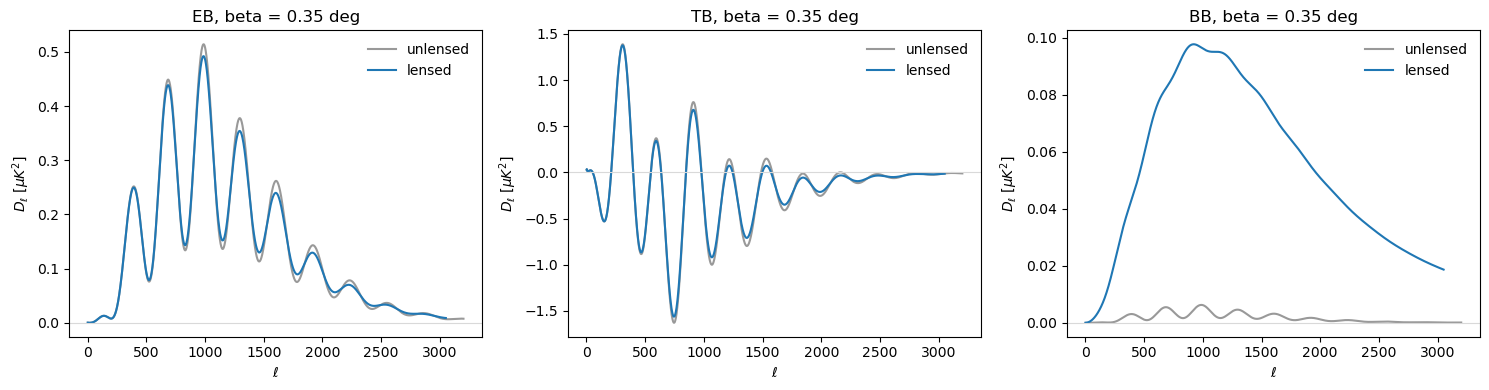

In [7]:
ell, ell_l = np.arange(unl.shape[0]), np.arange(lns.shape[0])
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col, name in zip(ax, [4, 5, 2], ["EB", "TB", "BB"]):
    a.plot(ell[2:], unl[2:, col], color="0.6", label="unlensed")
    a.plot(ell_l[2:], lns[2:, col], color="C0", label="lensed")
    a.axhline(0, color="0.85", lw=0.8)
    a.set_title(f"{name}, beta = {beta} deg"); a.set_xlabel(r"$\ell$"); a.set_ylabel(r"$D_\ell\ [\mu K^2]$")
    a.legend(frameon=False)
plt.tight_layout(); plt.show()

## 3. Check: $\beta = 0$ changes nothing

With $\beta=0$ the birefringence code never runs: BB, EB, TB must be exactly zero and all standard spectra must be
identical to a run that never mentions birefringence.

In [8]:
r_plain = camb.get_results(camb.set_params(**cosmo, lmax=3000))
r_zero = camb.get_results(camb.set_params(**cosmo, lmax=3000, birefringence_angle=0.0))
u0, l0 = r_zero.get_birefringence_cls(CMB_unit="muK"), r_zero.get_birefringence_cls(CMB_unit="muK", lensed=True)

check("beta = 0: max |BB, EB, TB| unlensed", np.max(np.abs(u0[:, [2, 4, 5]])), 0.0)
check("beta = 0: max |EB, TB| lensed", np.max(np.abs(l0[:, [4, 5]])), 0.0)
same = all(np.array_equal(getattr(r_plain, f)(CMB_unit="muK"), getattr(r_zero, f)(CMB_unit="muK"))
           for f in ["get_unlensed_scalar_cls", "get_lensed_scalar_cls"])
check("beta = 0: standard spectra differ from plain CAMB (1 = yes)", float(not same), 0.0)

PASS  beta = 0: max |BB, EB, TB| unlensed: 0.00e+00  (tolerance 0e+00)
PASS  beta = 0: max |EB, TB| lensed: 0.00e+00  (tolerance 0e+00)
PASS  beta = 0: standard spectra differ from plain CAMB (1 = yes): 0.00e+00  (tolerance 0e+00)


True

## 4. Check: unlensed spectra against the constant-$\beta$ formulas

For a constant angle the line-of-sight integral must reproduce (Eqs. 6–8 of arXiv:2305.13976, unrotated scalar BB$_0$ = 0)

$$C^{EE}_\ell=\cos^2 2\beta\,C^{EE}_{0,\ell},\quad C^{BB}_\ell=\sin^2 2\beta\,C^{EE}_{0,\ell},\quad
C^{EB}_\ell=\tfrac12\sin 4\beta\,C^{EE}_{0,\ell},\quad C^{TE}_\ell=\cos 2\beta\,C^{TE}_{0,\ell},\quad
C^{TB}_\ell=\sin 2\beta\,C^{TE}_{0,\ell}$$

where the subscript 0 is the $\beta=0$ run. This is an exact identity, so residuals should be at round-off ($\sim10^{-14}$).

In [9]:
def unlensed_checks(beta, lsb=1):
    p0 = camb.set_params(**cosmo, lmax=3000, lSampleBoost=lsb)
    p1 = camb.set_params(**cosmo, lmax=3000, lSampleBoost=lsb, birefringence_angle=beta)
    U0 = camb.get_results(p0).get_birefringence_cls(CMB_unit="muK")
    U1 = camb.get_results(p1).get_birefringence_cls(CMB_unit="muK")
    b = np.radians(beta); c, s = np.cos(2 * b), np.sin(2 * b)
    ell = np.arange(U1.shape[0]); m = (ell >= 30) & (ell <= 2900)
    mTE = m & (np.abs(U0[:, 3]) > 0.05 * np.abs(U0[:, 3]).max())   # skip TE zero crossings
    tag = f"beta = {beta:+g} deg, lSampleBoost = {lsb}"
    check(f"{tag}: EE / cos^2(2b) EE0", max_rel(U1[:, 1], c**2 * U0[:, 1], m), 1e-12)
    check(f"{tag}: BB / sin^2(2b) EE0", max_rel(U1[:, 2], s**2 * U0[:, 1], m), 1e-12)
    check(f"{tag}: EB / (1/2) sin(4b) EE0", max_rel(U1[:, 4], c * s * U0[:, 1], m), 1e-12)
    check(f"{tag}: TE / cos(2b) TE0", max_rel(U1[:, 3], c * U0[:, 3], mTE), 1e-12)
    check(f"{tag}: TB / sin(2b) TE0", max_rel(U1[:, 5], s * U0[:, 3], mTE), 1e-12)
    return U0, U1

U0, U1 = unlensed_checks(0.35)
_ = unlensed_checks(-0.35)          # sign
_ = unlensed_checks(5.0)            # large angle: tests the exact sin/cos, not just first order
_ = unlensed_checks(0.35, lsb=50)   # every multipole computed (no l-interpolation)

PASS  beta = +0.35 deg, lSampleBoost = 1: EE / cos^2(2b) EE0: 7.44e-15  (tolerance 1e-12)
PASS  beta = +0.35 deg, lSampleBoost = 1: BB / sin^2(2b) EE0: 9.21e-15  (tolerance 1e-12)
PASS  beta = +0.35 deg, lSampleBoost = 1: EB / (1/2) sin(4b) EE0: 9.33e-15  (tolerance 1e-12)
PASS  beta = +0.35 deg, lSampleBoost = 1: TE / cos(2b) TE0: 1.53e-14  (tolerance 1e-12)
PASS  beta = +0.35 deg, lSampleBoost = 1: TB / sin(2b) TE0: 1.37e-14  (tolerance 1e-12)
PASS  beta = -0.35 deg, lSampleBoost = 1: EE / cos^2(2b) EE0: 7.44e-15  (tolerance 1e-12)
PASS  beta = -0.35 deg, lSampleBoost = 1: BB / sin^2(2b) EE0: 9.21e-15  (tolerance 1e-12)
PASS  beta = -0.35 deg, lSampleBoost = 1: EB / (1/2) sin(4b) EE0: 9.33e-15  (tolerance 1e-12)
PASS  beta = -0.35 deg, lSampleBoost = 1: TE / cos(2b) TE0: 1.53e-14  (tolerance 1e-12)
PASS  beta = -0.35 deg, lSampleBoost = 1: TB / sin(2b) TE0: 1.37e-14  (tolerance 1e-12)
PASS  beta = +5 deg, lSampleBoost = 1: EE / cos^2(2b) EE0: 9.55e-15  (tolerance 1e-12)
PASS  beta = 

The same comparison as a figure, with residuals:

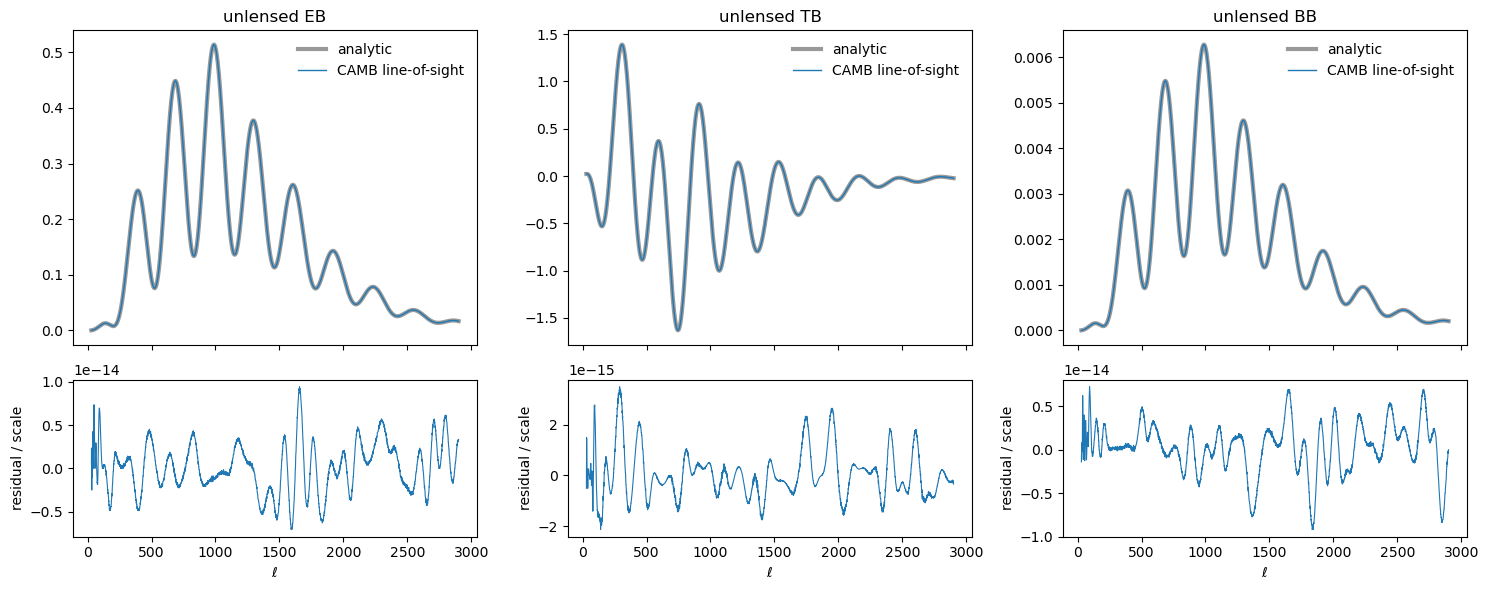

In [10]:
b = np.radians(beta); c, s = np.cos(2 * b), np.sin(2 * b)
ell = np.arange(U1.shape[0]); m = (ell >= 30) & (ell <= 2900)
fig, ax = plt.subplots(2, 3, figsize=(15, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for k, (col, th, name, norm) in enumerate([
        (4, c * s * U0[:, 1], "EB", np.abs(c * s * U0[:, 1])),
        (5, s * U0[:, 3], "TB", np.sqrt(U0[:, 0] * s**2 * U0[:, 1])),
        (2, s**2 * U0[:, 1], "BB", s**2 * U0[:, 1])]):
    ax[0, k].plot(ell[m], th[m], color="0.6", lw=3, label="analytic")
    ax[0, k].plot(ell[m], U1[m, col], color="C0", lw=1, label="CAMB line-of-sight")
    ax[0, k].set_title(f"unlensed {name}"); ax[0, k].legend(frameon=False)
    ax[1, k].plot(ell[m], (U1[m, col] - th[m]) / norm[m], color="C0", lw=0.8)
    ax[1, k].set_xlabel(r"$\ell$"); ax[1, k].set_ylabel("residual / scale")
plt.tight_layout(); plt.show()

## 5. Check: lensed spectra against the rotated lensed spectra of $\beta = 0$

Lensing and a constant rotation commute, so the lensed spectra must equal the $\beta=0$ lensed spectra rotated by $\beta$:

$$\tilde C^{EB}_\ell=\tfrac12\sin4\beta\,(\tilde C^{EE}_{0,\ell}-\tilde C^{BB}_{0,\ell}),\quad
\tilde C^{TB}_\ell=\sin2\beta\,\tilde C^{TE}_{0,\ell},\quad
\tilde C^{BB}_\ell=\cos^2 2\beta\,\tilde C^{BB}_{0,\ell}+\sin^2 2\beta\,\tilde C^{EE}_{0,\ell}$$

The code never uses these formulas (it lenses the unlensed BB, EB, TB directly), so agreement is an independent test of
the lensing. It is run for both lensing routines: the default and `AccurateBB=True`.

In [11]:
def lensed_checks(beta, accurate_bb=False):
    p0 = camb.set_params(**cosmo, lmax=3000); p0.Accuracy.AccurateBB = accurate_bb
    p1 = camb.set_params(**cosmo, lmax=3000, birefringence_angle=beta); p1.Accuracy.AccurateBB = accurate_bb
    L0 = camb.get_results(p0).get_birefringence_cls(CMB_unit="muK", lensed=True)
    L1 = camb.get_results(p1).get_birefringence_cls(CMB_unit="muK", lensed=True)
    b = np.radians(beta); c, s = np.cos(2 * b), np.sin(2 * b)
    ell = np.arange(L1.shape[0]); m = (ell >= 30) & (ell <= 2700)
    mTE = m & (np.abs(L0[:, 3]) > 0.05 * np.abs(L0[:, 3]).max())
    tag = f"lensed, beta = {beta:+g} deg, AccurateBB = {accurate_bb}"
    check(f"{tag}: EE", max_rel(L1[:, 1], c**2 * L0[:, 1] + s**2 * L0[:, 2], m), 1e-11)
    check(f"{tag}: BB", max_rel(L1[:, 2], c**2 * L0[:, 2] + s**2 * L0[:, 1], m), 1e-11)
    check(f"{tag}: EB", max_rel(L1[:, 4], c * s * (L0[:, 1] - L0[:, 2]), m), 1e-11)
    check(f"{tag}: TE", max_rel(L1[:, 3], c * L0[:, 3], mTE), 1e-11)
    check(f"{tag}: TB", max_rel(L1[:, 5], s * L0[:, 3], mTE), 1e-11)
    return L0, L1

L0, L1 = lensed_checks(0.35)
L0_acc, L1_acc = lensed_checks(0.35, accurate_bb=True)
L0_5, L1_5 = lensed_checks(5.0)

PASS  lensed, beta = +0.35 deg, AccurateBB = False: EE: 5.77e-15  (tolerance 1e-11)
PASS  lensed, beta = +0.35 deg, AccurateBB = False: BB: 8.69e-14  (tolerance 1e-11)
PASS  lensed, beta = +0.35 deg, AccurateBB = False: EB: 7.33e-15  (tolerance 1e-11)
PASS  lensed, beta = +0.35 deg, AccurateBB = False: TE: 1.39e-14  (tolerance 1e-11)
PASS  lensed, beta = +0.35 deg, AccurateBB = False: TB: 1.17e-14  (tolerance 1e-11)
PASS  lensed, beta = +0.35 deg, AccurateBB = True: EE: 1.67e-14  (tolerance 1e-11)
PASS  lensed, beta = +0.35 deg, AccurateBB = True: BB: 4.28e-13  (tolerance 1e-11)
PASS  lensed, beta = +0.35 deg, AccurateBB = True: EB: 1.22e-14  (tolerance 1e-11)
PASS  lensed, beta = +0.35 deg, AccurateBB = True: TE: 1.49e-14  (tolerance 1e-11)
PASS  lensed, beta = +0.35 deg, AccurateBB = True: TB: 1.39e-14  (tolerance 1e-11)
PASS  lensed, beta = +5 deg, AccurateBB = False: EE: 8.22e-15  (tolerance 1e-11)
PASS  lensed, beta = +5 deg, AccurateBB = False: BB: 2.79e-14  (tolerance 1e-11)
PAS

The same lensed comparison as a figure. Top row: CAMB's lensed spectra (blue) on top of the rotated $\beta=0$ lensed
spectra (grey), with the unlensed spectra dashed for reference. Bottom row: residuals for the three runs above.
EE, BB and EB residuals are fractional; TE and TB residuals are divided by $\sqrt{TT\cdot EE}$ and $\sqrt{TT\cdot BB}$,
because TE and TB cross zero.

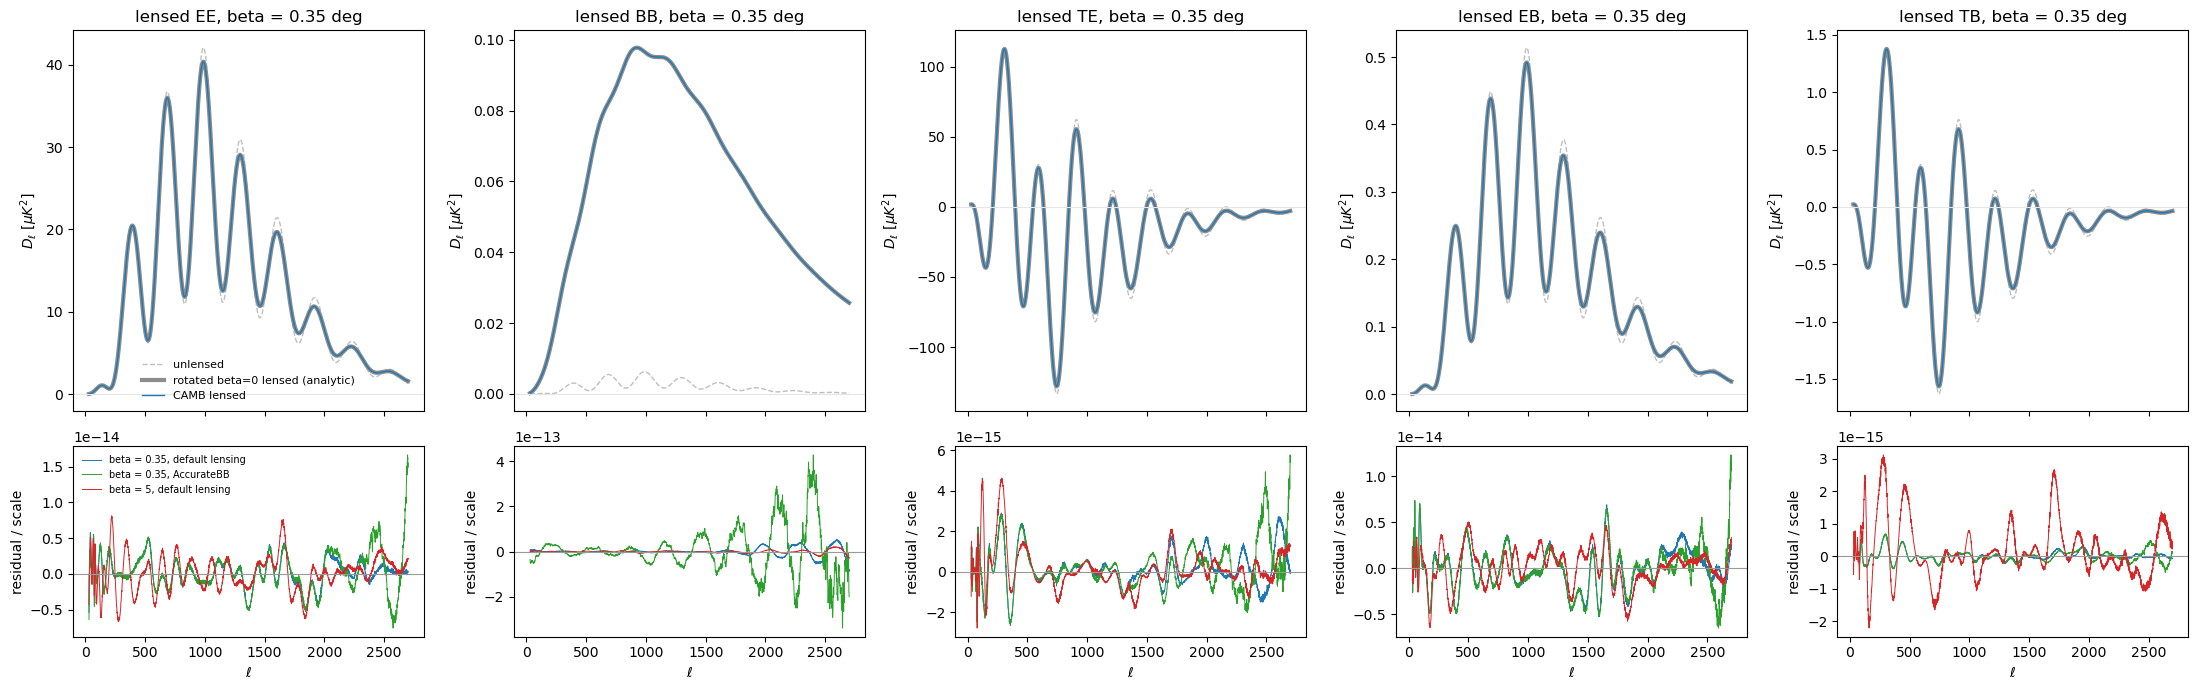

In [12]:
def rotated_lensed(L0, beta):
    # analytic lensed spectra: the beta = 0 lensed spectra rotated by beta (columns EE, BB, TE, EB, TB)
    b = np.radians(beta); c, s = np.cos(2 * b), np.sin(2 * b)
    return {"EE": c**2 * L0[:, 1] + s**2 * L0[:, 2], "BB": c**2 * L0[:, 2] + s**2 * L0[:, 1],
            "TE": c * L0[:, 3], "EB": c * s * (L0[:, 1] - L0[:, 2]), "TB": s * L0[:, 3]}

col = {"EE": 1, "BB": 2, "TE": 3, "EB": 4, "TB": 5}
runs = [(L0, L1, 0.35, "beta = 0.35, default lensing", "C0"),
        (L0_acc, L1_acc, 0.35, "beta = 0.35, AccurateBB", "C2"),
        (L0_5, L1_5, 5.0, "beta = 5, default lensing", "C3")]

ell = np.arange(L1.shape[0]); m = (ell >= 30) & (ell <= 2700)
fig, ax = plt.subplots(2, 5, figsize=(22, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
th = rotated_lensed(L0, 0.35)
for k, name in enumerate(["EE", "BB", "TE", "EB", "TB"]):
    a = ax[0, k]
    a.plot(ell[m], U1[:L1.shape[0], col[name]][m], color="0.75", ls="--", lw=1, label="unlensed")
    a.plot(ell[m], th[name][m], color="0.55", lw=3, label="rotated beta=0 lensed (analytic)")
    a.plot(ell[m], L1[m, col[name]], color="C0", lw=1, label="CAMB lensed")
    a.axhline(0, color="0.9", lw=0.8)
    a.set_title(f"lensed {name}, beta = 0.35 deg"); a.set_ylabel(r"$D_\ell\ [\mu K^2]$")
    if k == 0:
        a.legend(frameon=False, fontsize=8)
    r = ax[1, k]
    for L0r, L1r, bet, lab, colr in runs:
        thr = rotated_lensed(L0r, bet)
        if name == "TE":
            norm = np.sqrt(L0r[:, 0] * L0r[:, 1])
        elif name == "TB":
            norm = np.sqrt(L0r[:, 0] * np.abs(thr["BB"]))
        else:
            norm = np.abs(thr[name])
        r.plot(ell[m], (L1r[m, col[name]] - thr[name][m]) / norm[m], color=colr, lw=0.7, label=lab)
    r.axhline(0, color="0.6", lw=0.8); r.set_xlabel(r"$\ell$"); r.set_ylabel("residual / scale")
    r.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    if k == 0:
        r.legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

## 6. Check: Eqs. 36–37 use the same kernels as Eqs. 34–35

Naokawa & Namikawa show that lensed EB uses the same lensing operator as EE$-$BB (Eq. 34), and lensed TB the same as TE
(Eq. 35). With constant $\beta$ the unlensed EB is $\cos2\beta\sin2\beta$ times EE$-$BB of the $\beta=0$ run, so the
**lensing change** of EB must be exactly $\cos2\beta\sin2\beta$ times the lensing change of EE$-$BB at $\beta=0$
(and likewise TB versus TE). The ratio must be 1.

In [13]:
b = np.radians(beta); c, s = np.cos(2 * b), np.sin(2 * b)   # beta = 0.35 deg runs L0, L1
n = L1.shape[0]
Ub0 = U0[:n]; Ub1 = U1[:n]
dEB = L1[:, 4] - Ub1[:, 4]
dEmB0 = (L0[:, 1] - L0[:, 2]) - (Ub0[:, 1] - Ub0[:, 2])
dTB = L1[:, 5] - Ub1[:, 5]
dTE0 = L0[:, 3] - Ub0[:, 3]
ell = np.arange(n); m = (ell >= 30) & (ell <= 2700)
mEB = m & (np.abs(dEmB0) > 1e-3 * np.abs(dEmB0[m]).max())
mTB = m & (np.abs(dTE0) > 1e-3 * np.abs(dTE0[m]).max())
check("lensing change: dEB / [cos2b sin2b d(EE-BB)_0]", max_rel(dEB, c * s * dEmB0, mEB), 1e-9)
check("lensing change: dTB / [sin2b dTE_0]", max_rel(dTB, s * dTE0, mTB), 1e-9)
for l in (300, 800, 1300, 2000):
    print(f"   ell {l}: dEB = {dEB[l]:+.6e},  cos2b sin2b d(EE-BB)_0 = {c * s * dEmB0[l]:+.6e}")

PASS  lensing change: dEB / [cos2b sin2b d(EE-BB)_0]: 4.50e-12  (tolerance 1e-09)
PASS  lensing change: dTB / [sin2b dTE_0]: 8.46e-13  (tolerance 1e-09)
   ell 300: dEB = -1.178785e-04,  cos2b sin2b d(EE-BB)_0 = -1.178785e-04
   ell 800: dEB = +5.887593e-03,  cos2b sin2b d(EE-BB)_0 = +5.887593e-03
   ell 1300: dEB = -2.385056e-02,  cos2b sin2b d(EE-BB)_0 = -2.385056e-02
   ell 2000: dEB = -3.033725e-03,  cos2b sin2b d(EE-BB)_0 = -3.033725e-03


## 7. Check: the unlensed BB enters the lensing once (Eqs. 33–34)

Standard CAMB assumes no unlensed scalar BB. Here the rotated BB is passed to the lensing, which both lenses it and adds
it back once. Lensed BB must split exactly into the ordinary lensing B (rotated) plus the **lensed** rotated E power,
with nothing left over; and the rotated part must differ from its unlensed value, showing it really was lensed.

In [14]:
b = np.radians(beta); c, s = np.cos(2 * b), np.sin(2 * b)
part_lensB = c**2 * L0[:, 2]     # ordinary lensing B modes, rotated
part_rot = s**2 * L0[:, 1]       # lensed version of the rotation-generated BB
leftover = np.max(np.abs(L1[m, 2] - part_lensB[m] - part_rot[m]) / L1[m, 2])
check("lensed BB = rotated lensing B + lensed rotated BB, leftover / BB", leftover, 1e-11)
print("   ell   lensed BB   rotated part (lensed)   rotated part (unlensed)   share of BB")
for l in (300, 800, 1300, 2000):
    print(f"   {l:4d}   {L1[l, 2]:.5f}    {part_rot[l]:.6f}               {Ub1[l, 2]:.6f}                  {100 * part_rot[l] / L1[l, 2]:.1f}%")

PASS  lensed BB = rotated lensing B + lensed rotated BB, leftover / BB: 8.69e-14  (tolerance 1e-11)
   ell   lensed BB   rotated part (lensed)   rotated part (unlensed)   share of BB
    300   0.03000    0.001310               0.001307                  4.4%
    800   0.09114    0.002147               0.002062                  2.4%
   1300   0.08869    0.004329               0.004608                  4.9%
   2000   0.05090    0.001169               0.001199                  2.3%


## 8. Check: an independent lensing code (Eqs. 36–37 computed directly)

`camb.correlations.lensed_cls` is CAMB's separate **Python** implementation of the same curved-sky lensing. Because lensing
is linear, passing the unlensed EB in the EE slot (with BB = 0) returns Eq. 36 as lensed EE $-$ lensed BB, and passing
the unlensed TB in the TE slot returns Eq. 37. The two codes are not identical even for ordinary spectra, so the reference
is how well they agree on EE at $\beta=0$; the birefringence spectra should agree at the same level.

reference: Python vs Fortran lensing on ordinary EE at beta = 0: 5.0e-04
PASS  Eq. 36: lensed EB, Fortran vs Python, fractional: 6.53e-04  (tolerance 2e-03)
PASS  Eq. 37: lensed TB, Fortran vs Python, / sqrt(TT BB): 2.69e-05  (tolerance 2e-03)


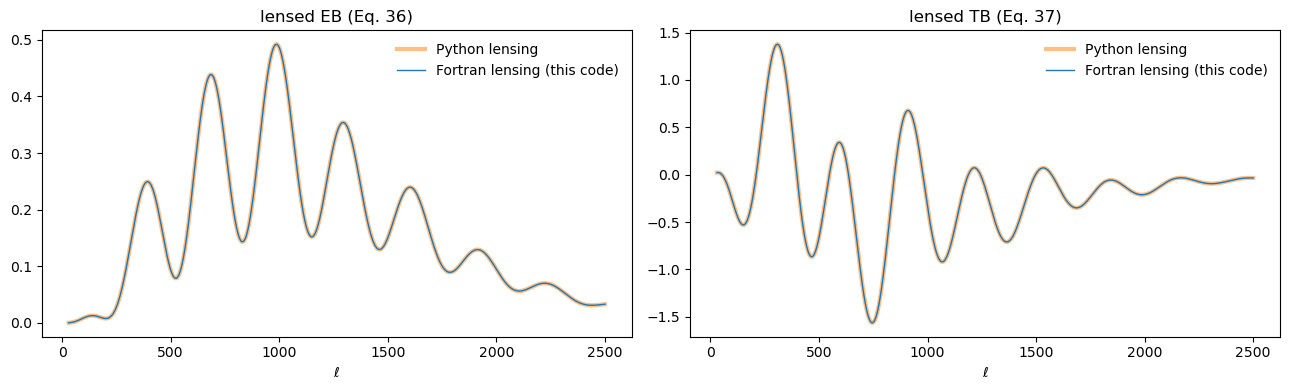

In [15]:
r4 = camb.get_results(camb.set_params(**cosmo, lmax=4000, birefringence_angle=beta))
U4 = r4.get_birefringence_cls(lmax=4000, CMB_unit="muK")
L4 = r4.get_birefringence_cls(CMB_unit="muK", lensed=True)
clpp = r4.get_lens_potential_cls(lmax=4000)[:, 0]

inp = np.zeros((4001, 4)); inp[:, 0] = U4[:, 0]; inp[:, 1] = U4[:, 4]; inp[:, 3] = U4[:, 5]
py = correlations.lensed_cls(inp, clpp, lmax=4000, lmax_lensed=3000)
EB_py, TB_py = py[:, 1] - py[:, 2], py[:, 3]

r4_0 = camb.get_results(camb.set_params(**cosmo, lmax=4000))
py0 = correlations.lensed_cls(r4_0.get_unlensed_scalar_cls(lmax=4000, CMB_unit="muK"),
                              r4_0.get_lens_potential_cls(lmax=4000)[:, 0], lmax=4000, lmax_lensed=3000)
EE_f0 = r4_0.get_lensed_scalar_cls(CMB_unit="muK")[:3001, 1]

ell = np.arange(3001); m = (ell >= 30) & (ell <= 2500)
ref = max_rel(py0[:, 1], EE_f0, m)
print(f"reference: Python vs Fortran lensing on ordinary EE at beta = 0: {ref:.1e}")
check("Eq. 36: lensed EB, Fortran vs Python, fractional", max_rel(L4[:3001, 4], EB_py, m), 3 * ref)
tb_scale = np.sqrt(L4[:3001, 0] * L4[:3001, 2])
check("Eq. 37: lensed TB, Fortran vs Python, / sqrt(TT BB)",
      np.max(np.abs(L4[:3001, 5][m] - TB_py[m]) / tb_scale[m]), 3 * ref)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, cam, pyc, name in zip(ax, [L4[:3001, 4], L4[:3001, 5]], [EB_py, TB_py], ["EB (Eq. 36)", "TB (Eq. 37)"]):
    a.plot(ell[m], pyc[m], color="C1", lw=3, alpha=0.5, label="Python lensing")
    a.plot(ell[m], cam[m], color="C0", lw=1, label="Fortran lensing (this code)")
    a.set_title(f"lensed {name}"); a.set_xlabel(r"$\ell$"); a.legend(frameon=False)
plt.tight_layout(); plt.show()

## 9. Check: parameter handling and limits of validity

In [16]:
import os

# .ini round trip through the Fortran reader
# written next to this notebook (the folder Jupyter runs it in), so you can open and inspect it
ini = os.path.abspath("biref_check.ini")
pars.write_ini(ini)
print("written:", ini)
print("ini line:", [line.strip() for line in open(ini) if "birefringence" in line])
# Compare two fresh runs: CAMB caches Bessel tables at the largest lmax used so far (4000 in section 8),
# which changes results at the 1e-10 level relative to a run made before that; so do not compare with `lns`.
eb_ini = camb.get_results(camb.read_ini(ini)).get_birefringence_cls(CMB_unit="muK", lensed=True)[:, 4]
eb_py = camb.get_results(pars).get_birefringence_cls(CMB_unit="muK", lensed=True)[:, 4]
mm = np.abs(eb_py) > 1e-3 * np.abs(eb_py).max()
check(".ini round trip: lensed EB, fractional difference", max_rel(eb_ini, eb_py, mm), 1e-8)

# tensors are not rotated (documented limitation): tensor spectra must not change with beta
pt = camb.set_params(**cosmo, lmax=3000, r=0.05, WantTensors=True)
t0 = camb.get_results(pt).get_tensor_cls(CMB_unit="muK"); pt.birefringence_angle = beta
t1 = camb.get_results(pt).get_tensor_cls(CMB_unit="muK")
check("tensors unchanged by beta (max |difference|)", np.max(np.abs(t1 - t0)), 0.0)

# curved models are not supported and must raise an error
try:
    camb.get_results(camb.set_params(**cosmo, lmax=3000, omk=0.01, birefringence_angle=beta))
    check("curved model raises an error (1 = no error)", 1.0, 0.0)
except camb.CAMBError as e:
    print("   curved model error:", str(e).splitlines()[-1])
    check("curved model raises an error (1 = no error)", 0.0, 0.0)

written: /Users/debabrata/Documents/WORKS/WORKS/Cosmic_Birefringence/CAMB_BIREFRINGENCE_2.0.5_varying_beta/tutorials_DA/biref_check.ini
ini line: ['birefringence_angle=0.35']
PASS  .ini round trip: lensed EB, fractional difference: 0.00e+00  (tolerance 1e-08)
PASS  tensors unchanged by beta (max |difference|): 0.00e+00  (tolerance 0e+00)
   curved model error: birefringence_angle is only implemented for flat models
PASS  curved model raises an error (1 = no error): 0.00e+00  (tolerance 0e+00)


## 10. Time-varying rotation $\beta(z)$

Instead of one angle you can give a table $\beta(z)$: the rotation, in degrees, of a photon emitted at redshift $z$.
CAMB interpolates it (cubic spline in $z$) at every line-of-sight time step $\tau_n$, so the integral becomes
$\Delta_E = \sum_n S_E\, j_\ell \cos 2\beta(\tau_n)\,\Delta\tau$ and $\Delta_B = \sum_n S_E\, j_\ell \sin 2\beta(\tau_n)\,\Delta\tau$
(Eq. 7 of arXiv:2506.20824). Lensing is unchanged: the same curved-sky lensing acts on the unlensed spectra.

- `pars.set_birefringence_table(z, beta)`: set the table (z strictly increasing); it overrides `birefringence_angle`.
  Below the first and above the last $z$ the end values are used. `pars.set_birefringence_table()` removes it.
- `camb.birefringence.axion_birefringence_table(pars, mass_ev, beta_ini)`: solves
  $f'' + (3 + d\ln H/d\ln a) f' + (m/H)^2 f = 0$ ($f=\phi/\phi_{\rm ini}$, $'=d/d\ln a$) in the background of `pars` and
  returns $(z, \beta(z))$ with $\beta(z) = \beta_{\rm ini}[f(z) - f(0)]$, $\beta_{\rm ini} = -g\phi_{\rm ini}/2$.

**Accuracy:** with a table use `lSampleBoost=50` (CAMB's default $\ell$ interpolation is tuned for smooth spectra,
about $10^{-6}$ error), and `AccuracyBoost=2` for $m \gtrsim 10^{-27}$ eV, where $\beta$ oscillates during recombination.

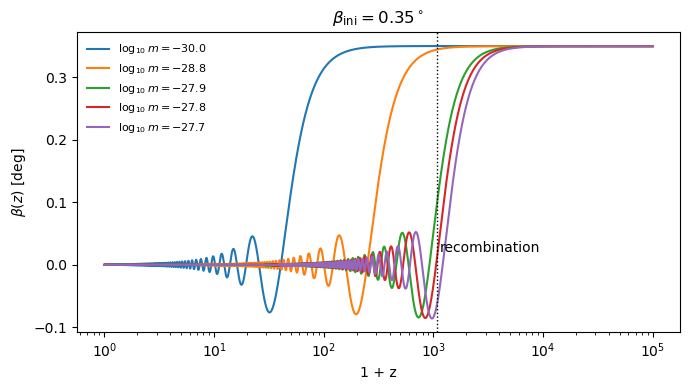

In [17]:
from camb.birefringence import axion_birefringence_table

p_bg = camb.set_params(**cosmo, lmax=3000)
bg = camb.get_background(p_bg)              # reuse the background for many masses
masses = [-30.0, -28.8, -27.9, -27.8, -27.7]  # log10(m / eV)
tables = {lm: axion_birefringence_table(p_bg, 10**lm, beta, results=bg) for lm in masses}

def run_table(table=None, angle=0.0, lmax=3000, boost=1.0):
    p = camb.set_params(**cosmo, lmax=lmax, lSampleBoost=50, AccuracyBoost=boost, birefringence_angle=angle)
    if table is not None:
        p.set_birefringence_table(*table)
    r = camb.get_results(p)
    U, L = r.get_birefringence_cls(CMB_unit="muK"), r.get_birefringence_cls(CMB_unit="muK", lensed=True)
    return U[:lmax + 1], L[:lmax + 1]

fig, ax = plt.subplots(figsize=(7, 4))
for lm, (z, b) in tables.items():
    ax.semilogx(1 + z, b, label=rf"$\log_{{10}} m = {lm}$")
ax.axvline(1091, color="k", ls=":", lw=1); ax.text(1150, 0.02, "recombination")
ax.set_xlabel("1 + z"); ax.set_ylabel(r"$\beta(z)$ [deg]"); ax.set_title(rf"$\beta_{{\rm ini}} = {beta}^\circ$")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

**Check (a): a constant table is the constant angle.** With the same sampling the two must agree to round-off.
**Check (b): $\beta \to -\beta$** flips EB and TB exactly and leaves TT, EE, BB, TE unchanged.
**Check (c): input validation** of the table.

In [18]:
zc = np.array([0.0, 10.0, 1e3, 1e5])
Uk, Lk = run_table((zc, np.full(4, beta)))
Ua, La = run_table(angle=beta)
mk = np.abs(Ua[:, 4]) > 1e-3 * np.abs(Ua[:, 4]).max()
check("beta(z) = const table vs constant angle: unlensed EB", max_rel(Uk[:, 4], Ua[:, 4], mk), 1e-12)
check("beta(z) = const table vs constant angle: lensed BB", max_rel(Lk[2:, 2], La[2:, 2], slice(None)), 1e-12)

z, b = tables[-27.9]
Up, Lp = run_table((z, b)); Um, Lm = run_table((z, -b))
check("beta -> -beta: EB, TB change sign (max |sum| / max |EB|)",
      np.max(np.abs(Lp[:, 4:] + Lm[:, 4:])) / np.abs(Lp[:, 4]).max(), 1e-12)
check("beta -> -beta: TT, EE, BB, TE unchanged (max rel.)",
      np.max(np.abs(Lp[2:, :4] - Lm[2:, :4]) / np.abs(Lp[2:, :4]).max(axis=0)), 1e-12)

bad = 0
for args in [(np.array([1.0, 0.0]), np.zeros(2)), (np.zeros(1), np.zeros(1)), (np.arange(3.0), np.zeros(2))]:
    try:
        camb.CAMBparams().set_birefringence_table(*args); bad += 1
    except camb.CAMBValueError as e:
        print("   rejected:", e)
check("bad tables rejected (number accepted)", float(bad), 0.0)

PASS  beta(z) = const table vs constant angle: unlensed EB: 2.22e-16  (tolerance 1e-12)
PASS  beta(z) = const table vs constant angle: lensed BB: 0.00e+00  (tolerance 1e-12)
PASS  beta -> -beta: EB, TB change sign (max |sum| / max |EB|): 0.00e+00  (tolerance 1e-12)
PASS  beta -> -beta: TT, EE, BB, TE unchanged (max rel.): 0.00e+00  (tolerance 1e-12)
   rejected: birefringence table redshifts must be strictly increasing
   rejected: z and beta must be 1D arrays of the same length (at least 2 points)
   rejected: z and beta must be 1D arrays of the same length (at least 2 points)
PASS  bad tables rejected (number accepted): 0.00e+00  (tolerance 0e+00)


True

**Check (d): light field.** For $m = 10^{-30}$ eV the field is frozen until after recombination, so CMB photons from
$z\approx1100$ all see $\beta(z_{\rm rec})$: for $\ell \geq 100$ EB must equal the constant-$\beta$ EB at that angle.
At low $\ell$ (reionization photons, $z\lesssim10$) EB is smaller, because the field has started rolling by then.

In [19]:
z, b = tables[-30.0]
b_rec = np.interp(1090, z, b)
Ul, _ = run_table((z, b)); Uc, _ = run_table(angle=b_rec)
ell = np.arange(Ul.shape[0]); m = (ell >= 100) & (ell <= 2900)
print(f"beta(z=1090) = {b_rec:.5f} deg, beta(z=10) = {np.interp(10, z, b):.5f} deg")
check("light field: EB vs constant beta(z_rec), ell 100-2900", max_rel(Ul[:, 4], Uc[:, 4], m), 1e-4)
print(f"   low ell: EB / constant-beta EB at ell = 5: {Ul[5, 4] / Uc[5, 4]:.3f}")

beta(z=1090) = 0.35032 deg, beta(z=10) = -0.00662 deg
PASS  light field: EB vs constant beta(z_rec), ell 100-2900: 4.94e-05  (tolerance 1e-04)
   low ell: EB / constant-beta EB at ell = 5: 0.026


**Check (e): heavier fields** (compare Fig. 6 of Nakatsuka, Namikawa & Komatsu, arXiv:2203.08560). As $m$ grows the field
oscillates earlier: $\beta(z_{\rm rec})$ drops, EB is suppressed, its peaks shift, and for $\log_{10}m=-27.7$ it changes sign.

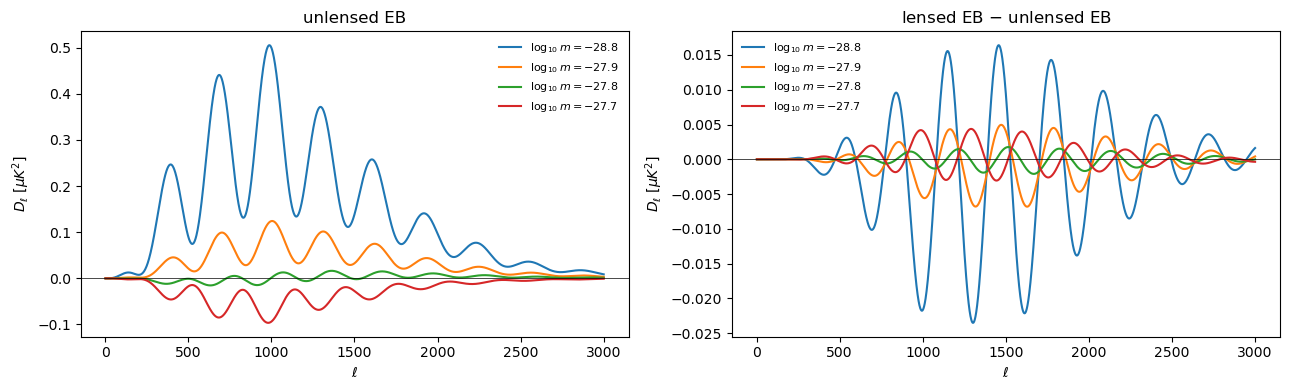

PASS  max |EB| decreases with mass (1 = no): 0.00e+00  (tolerance 0e+00)
PASS  log m = -27.7: EB negative at ell = 1000 (1 = no): 0.00e+00  (tolerance 0e+00)


True

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
eb = {}
for lm in masses[1:]:
    U, L = run_table(tables[lm]); eb[lm] = U[:, 4]
    ax[0].plot(ell[2:], U[2:, 4], label=rf"$\log_{{10}} m = {lm}$")
    ax[1].plot(ell[2:], L[2:, 4] - U[2:, 4], label=rf"$\log_{{10}} m = {lm}$")
ax[0].set_title("unlensed EB"); ax[1].set_title("lensed EB $-$ unlensed EB")
for a in ax:
    a.axhline(0, color="k", lw=0.5); a.set_xlabel(r"$\ell$"); a.set_ylabel(r"$D_\ell\ [\mu K^2]$"); a.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

mx = [np.abs(eb[lm][300:1800]).max() for lm in masses[1:4]]
check("max |EB| decreases with mass (1 = no)", float(not (mx[0] > mx[1] > mx[2])), 0.0)
check("log m = -27.7: EB negative at ell = 1000 (1 = no)", float(not eb[-27.7][1000] < 0), 0.0)

**Check (f): lensing with $\beta(z)$ against the independent Python lensing**, as in section 8, and
**check (g): convergence** with `AccuracyBoost` for a heavy field.

In [18]:
p4 = camb.set_params(**cosmo, lmax=4000, lSampleBoost=50)
p4.set_birefringence_table(*tables[-27.9])
r4t = camb.get_results(p4)
U4t = r4t.get_birefringence_cls(lmax=4000, CMB_unit="muK"); L4t = r4t.get_birefringence_cls(CMB_unit="muK", lensed=True)
inp = np.zeros((4001, 4)); inp[:, 0] = U4t[:, 0]; inp[:, 1] = U4t[:, 4]; inp[:, 3] = U4t[:, 5]
pyt = correlations.lensed_cls(inp, r4t.get_lens_potential_cls(lmax=4000)[:, 0], lmax=4000, lmax_lensed=3000)
ell = np.arange(3001); m = (ell >= 30) & (ell <= 2500)
check("beta(z) lensed EB, Fortran vs Python, / max |EB|",
      np.max(np.abs(L4t[:3001, 4][m] - (pyt[:, 1] - pyt[:, 2])[m])) / np.abs(L4t[:3001, 4][m]).max(), 1e-3)
check("beta(z) lensed TB, Fortran vs Python, / max |TB|",
      np.max(np.abs(L4t[:3001, 5][m] - pyt[:, 3][m])) / np.abs(L4t[:3001, 5][m]).max(), 1e-3)

U1, _ = run_table(tables[-27.8], boost=1); U2, _ = run_table(tables[-27.8], boost=2)
check("log m = -27.8: EB change AccuracyBoost 1 -> 2, / max |EB|",
      np.max(np.abs(U1[100:2900, 4] - U2[100:2900, 4])) / np.abs(U2[100:2900, 4]).max(), 2e-3)

PASS  beta(z) lensed EB, Fortran vs Python, / max |EB|: 1.66e-04  (tolerance 1e-03)
PASS  beta(z) lensed TB, Fortran vs Python, / max |TB|: 1.21e-04  (tolerance 1e-03)


PASS  log m = -27.8: EB change AccuracyBoost 1 -> 2, / max |EB|: 4.73e-04  (tolerance 2e-03)


True

## Summary

In [19]:
n_pass = sum(r[3] for r in results_table)
print(f"{n_pass} of {len(results_table)} checks passed\n")
for name, value, tol, ok in results_table:
    print(f"{'PASS' if ok else 'FAIL'}  {value:9.2e}  <= {tol:7.0e}   {name}")
assert n_pass == len(results_table), "Some checks failed"

57 of 57 checks passed

PASS   0.00e+00  <=   0e+00   beta = 0: max |BB, EB, TB| unlensed
PASS   0.00e+00  <=   0e+00   beta = 0: max |EB, TB| lensed
PASS   0.00e+00  <=   0e+00   beta = 0: standard spectra differ from plain CAMB (1 = yes)
PASS   7.44e-15  <=   1e-12   beta = +0.35 deg, lSampleBoost = 1: EE / cos^2(2b) EE0
PASS   9.21e-15  <=   1e-12   beta = +0.35 deg, lSampleBoost = 1: BB / sin^2(2b) EE0
PASS   9.33e-15  <=   1e-12   beta = +0.35 deg, lSampleBoost = 1: EB / (1/2) sin(4b) EE0
PASS   1.53e-14  <=   1e-12   beta = +0.35 deg, lSampleBoost = 1: TE / cos(2b) TE0
PASS   1.37e-14  <=   1e-12   beta = +0.35 deg, lSampleBoost = 1: TB / sin(2b) TE0
PASS   7.44e-15  <=   1e-12   beta = -0.35 deg, lSampleBoost = 1: EE / cos^2(2b) EE0
PASS   9.21e-15  <=   1e-12   beta = -0.35 deg, lSampleBoost = 1: BB / sin^2(2b) EE0
PASS   9.33e-15  <=   1e-12   beta = -0.35 deg, lSampleBoost = 1: EB / (1/2) sin(4b) EE0
PASS   1.53e-14  <=   1e-12   beta = -0.35 deg, lSampleBoost = 1: TE / cos(2

## Tips

- **Units:** `CMB_unit="muK"` for $\mu K^2$; default $D_\ell$; `raw_cl=True` for $C_\ell$.
- **Columns:** `TT, EE, BB, TE, EB, TB = cls.T`.
- **Lensed spectra:** use `get_birefringence_cls(lensed=True)` for EB, TB. The standard `get_lensed_scalar_cls()` and
  `get_total_cls()` already include the lensed rotated BB, but have no EB/TB columns.
- **Accuracy:** for templates at high $\ell$, `lens_potential_accuracy` and `AccurateBB=True` work as in standard CAMB;
  `lmax` of at least 1000 above the highest multipole you use keeps the lensing tail well behaved.
- **Limitations:** flat models only; tensors are not rotated; a $\beta(z)$ table can only be set from Python
  (not from `.ini` files).
- **$\beta(z)$ accuracy:** `lSampleBoost=50` with tables; `AccuracyBoost=2` for $m \gtrsim 10^{-27}$ eV.